In [22]:
!pip install "rembg[cpu]" pillow-avif-plugin transformers torch

In [23]:
import base64, io, json
from collections import defaultdict

import pillow_avif  # must come before opening AVIF files
import torch
from PIL import Image
from rembg import remove, new_session
from transformers import AutoImageProcessor, AutoModelForImageClassification

NAME = "wargoninnovation/wargon-clothing-classifier"
processor = AutoImageProcessor.from_pretrained(NAME)
model = AutoModelForImageClassification.from_pretrained(NAME).eval()
session = new_session("u2net")  # loaded once; reused on warm Lambda calls

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

  0%|                                               | 0.00/176M [00:00<?, ?B/s]

In [24]:
id2label = {
    0: 'Blazer', 1: 'Blouse', 2: 'Cardigan', 3: 'Dress', 4: 'Hoodie',
    5: 'Jacket', 6: 'Jeans', 7: 'Nightgown', 8: 'Outerwear', 9: 'Pajamas',
    10: 'Rain jacket', 11: 'Rain trousers', 12: 'Robe', 13: 'Shirt',
    14: 'Shorts', 15: 'Skirt', 16: 'Sweater', 17: 'T-shirt', 18: 'Tank top',
    19: 'Tights', 20: 'Top', 21: 'Training top', 22: 'Trousers',
    23: 'Tunic', 24: 'Vest', 25: 'Winter jacket', 26: 'Winter trousers',
}

categories = {
    "head": [],
    "undershirt": ['Blouse', 'Shirt', 'T-shirt', 'Tank top', 'Top', 'Tunic'],
    "overshirt": ['Blazer', 'Cardigan', 'Hoodie', 'Jacket', 'Outerwear',
                  'Rain jacket', 'Sweater', 'Training top', 'Vest', 'Winter jacket'],
    "legs": ['Jeans', 'Rain trousers', 'Shorts', 'Skirt', 'Tights',
             'Trousers', 'Winter trousers'],
    "shoe": [],
    "misc": ['Dress', 'Nightgown', 'Pajamas', 'Robe'],
}
label_to_category = {l: c for c, ls in categories.items() for l in ls}
id_to_category = {i: label_to_category[n] for i, n in id2label.items()}
assert len(label_to_category) == len(id2label) == 27

In [68]:
import numpy as np
from PIL import ImageFilter

def cut_out(img):
    img = img.copy()
    img.thumbnail((1024, 1024))
    return remove(img, session=session)          # RGBA, transparent background

def flatten(cutout):
    white = Image.new("RGBA", cutout.size, (255, 255, 255, 255))
    return Image.alpha_composite(white, cutout).convert("RGB")

def remove_background(img):                      # kept so Cell 6 still works
    return flatten(cut_out(img))

import colorsys

def color_name(rgb):
    r, g, b = (v / 255 for v in rgb)
    h, s, v = colorsys.rgb_to_hsv(r, g, b)
    h *= 360

    # near-neutral colors: decided by brightness only
    if v < 0.15:
        return "black"
    if s < 0.12:
        return "white" if v > 0.9 else "light gray" if v > 0.7 else "gray" if v > 0.35 else "charcoal"

    # hue family
    if h < 15 or h >= 345:   base = "red"
    elif h < 40:             base = "orange"
    elif h < 65:             base = "yellow"
    elif h < 165:            base = "green"
    elif h < 195:            base = "teal"
    elif h < 255:            base = "blue"
    elif h < 290:            base = "purple"
    else:                    base = "pink"

    # warm hues that are dark or dull are really browns and tans
    if base in ("red", "orange", "yellow") and v < 0.6:
        base = "brown"
    elif base in ("orange", "yellow") and s < 0.35 and v >= 0.6:
        base = "tan" if v < 0.85 else "beige"

    # shade modifier
    if base in ("brown", "tan", "beige"):
        return base
    if v < 0.38:
        return "dark " + base
    if s < 0.3:
        return "muted " + base
    if v > 0.85 and s < 0.5:
        return "light " + base
    return base

def get_palette(cutout, max_colors=6, min_share=0.10, merge_names=True):
    """Garment colors covering at least `min_share` of the garment pixels, most common first."""
    alpha = cutout.getchannel("A").filter(ImageFilter.MinFilter(9))
    mask = np.array(alpha) > 250
    pixels = np.array(cutout.convert("RGB"))[mask]
    if len(pixels) == 0:
        return []
    if len(pixels) > 50000:
        pixels = pixels[np.random.default_rng(0).choice(len(pixels), 50000, replace=False)]

    small = Image.fromarray(pixels.reshape(-1, 1, 3).astype("uint8"))
    q = small.quantize(colors=max_colors, method=Image.Quantize.MEDIANCUT)
    pal = q.getpalette()

    clusters = []
    for count, idx in sorted(q.getcolors(), reverse=True):
        rgb = tuple(int(v) for v in pal[idx * 3: idx * 3 + 3])
        clusters.append({"rgb": rgb, "name": color_name(rgb), "share": count / len(pixels)})

    if merge_names:
        merged = {}
        for c in clusters:                     # clusters are sorted, so the first rgb per name is the largest
            if c["name"] in merged:
                merged[c["name"]]["share"] += c["share"]
            else:
                merged[c["name"]] = dict(c)
        clusters = sorted(merged.values(), key=lambda c: c["share"], reverse=True)

    kept = [c for c in clusters if c["share"] >= min_share]
    if not kept:                               # never return an empty palette
        kept = clusters[:1]

    return [{"hex": "#%02x%02x%02x" % c["rgb"], "rgb": c["rgb"],
             "name": c["name"], "share": round(c["share"], 3)} for c in kept]

def color_family(palette):
    fam = defaultdict(float)
    for c in palette:
        fam[c["name"].split()[-1]] += c["share"]
    return dict(sorted(fam.items(), key=lambda kv: kv[1], reverse=True))

# ---- classification ----
def classify(img, remove_bg=True, top_k=5, min_color_share=0.10):
    img = img.convert("RGB")
    palette = []
    if remove_bg:
        cutout = cut_out(img)
        palette = get_palette(cutout, min_share=min_color_share)
        img = flatten(cutout)

    inputs = processor(img, return_tensors="pt")
    with torch.no_grad():
        probs = model(**inputs).logits.softmax(-1)[0]

    cat_probs = defaultdict(float)
    for i, p in enumerate(probs.tolist()):
        cat_probs[id_to_category[i]] += p
    best_cat = max(cat_probs, key=cat_probs.get)

    ids = [i for i in id2label if id_to_category[i] == best_cat]
    top_id = max(ids, key=lambda i: probs[i].item())

    top = probs.topk(top_k)
    return {
        "category": best_cat,
        "item": id2label[top_id],
        "confidence": round(probs[top_id].item(), 4),
        "raw_top_item": id2label[probs.argmax().item()],
        "palette": palette,
        "dominant_color": palette[0]["name"] if palette else None,
        "color_family": color_family(palette),   # <-- added
        "top_k": [
            {"item": id2label[i.item()], "category": id_to_category[i.item()],
             "prob": round(p.item(), 4)}
            for p, i in zip(top.values, top.indices)
        ],
        "category_probs": {c: round(p, 4) for c, p in cat_probs.items() if p > 0},
    }

def describe(result, min_family_share=0.10):
    families = [f for f, s in result["color_family"].items() if s >= min_family_share]
    color = " and ".join(families[:2]) if families else "unknown-colored"
    article = "an" if color[0] in "aeiou" else "a"
    return f"This is {article} {color} {result['item'].lower()} ({result['category']})."

In [51]:
def handler(event, context):
    body = event.get("body", event)
    if isinstance(body, str):
        body = json.loads(body)
    img = Image.open(io.BytesIO(base64.b64decode(body["image"])))
    result = classify(img, remove_bg=body.get("remove_bg", True))
    return {"statusCode": 200, "body": json.dumps(result)}

In [52]:
path = r"C:\Users\miles\OneDrive\Desktop\eece 411\final project\TMOYZQ-Men-Plaid-Dress-Shirt-Classic-Long-Sleeve-Button-Down-Business-Work-Casual-Slim-Fit-Plain-Flannel-Shirts-for-Men_a65c6299-6534-4a20-bd6b-94eaf3f58f8f.9a9e5bbfc2b9f2410dc713eb2e.jpeg"  # your full path
img = Image.open(path)

for flag in (False, True):
    r = classify(img, remove_bg=flag)
    print(f"remove_bg={flag}: {r['category']} / {r['item']} ({r['confidence']:.1%})  raw top: {r['raw_top_item']}")
    print("   ", r["top_k"][:3])

remove_bg=False: overshirt / Cardigan (29.8%)  raw top: Cardigan
    [{'item': 'Cardigan', 'category': 'overshirt', 'prob': 0.2984}, {'item': 'Top', 'category': 'undershirt', 'prob': 0.1609}, {'item': 'Pajamas', 'category': 'misc', 'prob': 0.052}]
remove_bg=True: overshirt / Cardigan (29.6%)  raw top: Cardigan
    [{'item': 'Cardigan', 'category': 'overshirt', 'prob': 0.2957}, {'item': 'Top', 'category': 'undershirt', 'prob': 0.148}, {'item': 'Pajamas', 'category': 'misc', 'prob': 0.0498}]


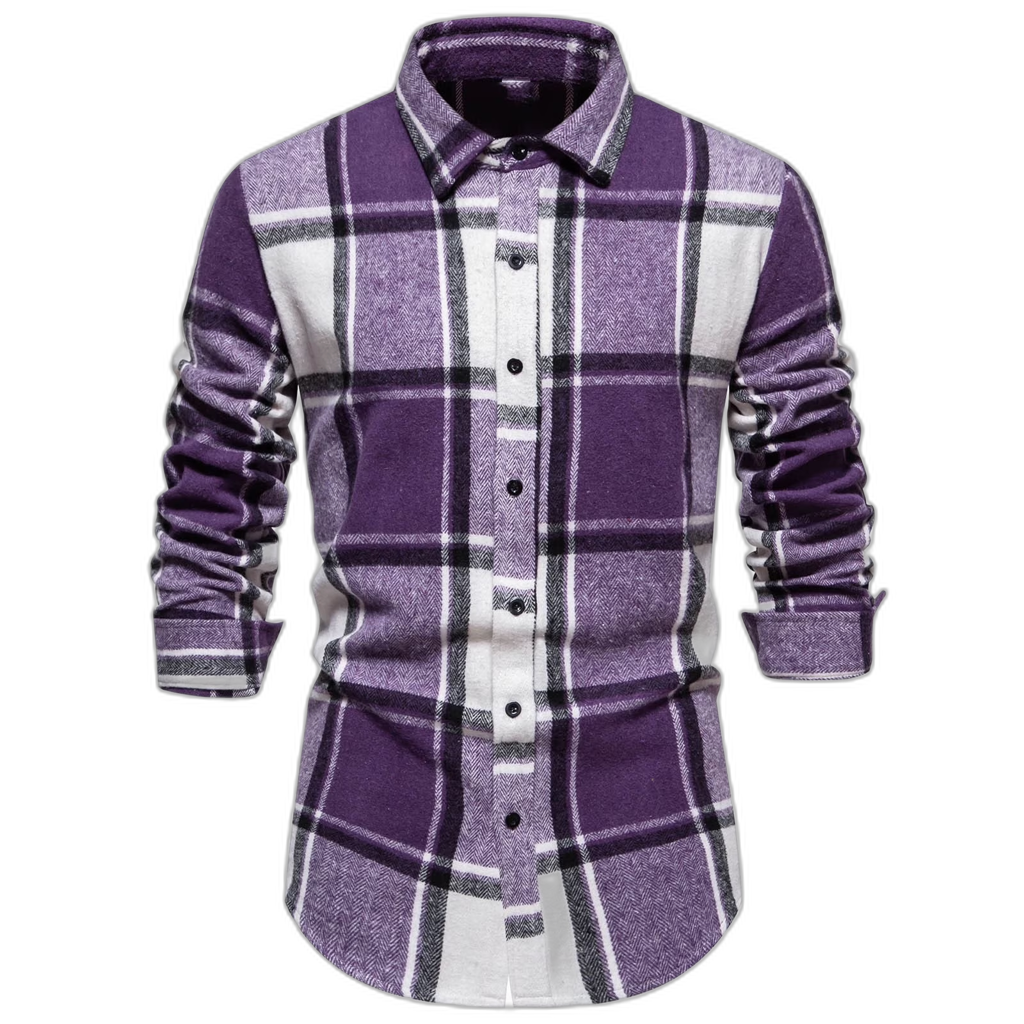

In [53]:
remove_background(img)  # last expression displays the image in the notebook

In [54]:
with open(path, "rb") as f:
    event = {"body": json.dumps({"image": base64.b64encode(f.read()).decode()})}
print(handler(event, None))

{'statusCode': 200, 'body': '{"category": "overshirt", "item": "Cardigan", "confidence": 0.2957, "raw_top_item": "Cardigan", "palette": [{"hex": "#45334f", "rgb": [69, 51, 79], "name": "dark purple", "share": 0.37}, {"hex": "#7a6a87", "rgb": [122, 106, 135], "name": "muted purple", "share": 0.334}, {"hex": "#584166", "rgb": [88, 65, 102], "name": "purple", "share": 0.163}, {"hex": "#dedbe1", "rgb": [222, 219, 225], "name": "light gray", "share": 0.132}], "dominant_color": "dark purple", "top_k": [{"item": "Cardigan", "category": "overshirt", "prob": 0.2957}, {"item": "Top", "category": "undershirt", "prob": 0.148}, {"item": "Pajamas", "category": "misc", "prob": 0.0498}, {"item": "Jacket", "category": "overshirt", "prob": 0.0488}, {"item": "Blazer", "category": "overshirt", "prob": 0.0464}], "category_probs": {"overshirt": 0.5429, "undershirt": 0.2087, "misc": 0.1542, "legs": 0.0943}}'}


In [69]:
result = classify(Image.open(path), remove_bg=True)

category = result["category"]
item = result["item"]
colors = result["color_family"]

print(category, item, colors)
# overshirt Cardigan {'purple': 0.867, 'gray': 0.132}
print(describe(result))

overshirt Cardigan {'purple': 0.867, 'gray': 0.132}
This is a purple and gray cardigan (overshirt).
